# 😷 MaskVision — זיהוי מסכות

מחברת לאימון CNN עם שתי מחלקות: **עם מסכה / בלי מסכה**. תמונות מהמחלקה `incorrect_mask` אינן משתתפות באימון, באימות או בהערכה.

הריצו לפי הסדר ב־Colab. מומלץ לבחור Runtime → Change runtime type → GPU.

החלוקה היא אקראית לפי קבצים. המחברת אינה בודקת כפילויות או זהויות בין הקבוצות; יש להתחשב בכך בפירוש מדדי ההערכה.


In [1]:
"""
תא 1 — ספריות והגדרות.
ייבוא הספריות, הגדרת גודל התמונות, מספר מחזורי האימון וזרע אקראי.
"""

import random
import shutil
import zipfile
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 25
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
"""
תא 2 — חיבור ל־Google Drive.
חיבור ל־Drive והגדרת תיקיית הפרויקט לשמירת המודל והתוצאות.
"""

from google.colab import drive
drive.mount('/content/drive')
project_dir = Path('/content/drive/MyDrive/MaskVision-AI-3')
project_dir.mkdir(parents=True, exist_ok=True)
print('Project directory:', project_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory: /content/drive/MyDrive/MaskVision-AI-3


In [3]:
"""
תא 3 — טעינת המאגר וחילוץ התמונות.
איתור FaceMask-3.zip, העתקתו לדיסק המקומי וחילוץ התמונות. העיבוד נעשה מקומית כדי להימנע מקריאות רבות ל־Drive.
"""

zip_name = 'FaceMask-3.zip'
zip_path = project_dir / zip_name
if not zip_path.is_file():
    zip_path = Path('/content/drive/MyDrive') / zip_name
if not zip_path.is_file():
    raise FileNotFoundError(f'Dataset not found: {zip_name}')

local_zip = Path('/content/maskvision_local.zip')
print('Copying ZIP to Colab...', flush=True)
shutil.copy2(zip_path, local_zip)
extract_dir = Path('/content/maskvision_source')
print('Extracting images...', flush=True)
with zipfile.ZipFile(local_zip) as archive:
    archive.extractall(extract_dir)
data_root = extract_dir / 'FMD_DATASET'
if not data_root.is_dir():
    raise FileNotFoundError(f'Missing dataset folder: {data_root}')
print('Dataset ready:', data_root)


Copying ZIP to Colab...
Extracting images...
Dataset ready: /content/maskvision_source/FMD_DATASET


In [5]:
"""
תא 4 — הגדרת שתי המחלקות.
איסוף תמונות רק מהתיקיות with_mask ו־without_mask.
תמונות מסכה לא תקינה אינן משתתפות באימון, באימות או בהערכה.
"""

class_names = ['with_mask', 'without_mask']
image_extensions = {'.jpg', '.jpeg', '.png'}
class_images = {'with_mask': [], 'without_mask': []}

for class_name in class_names:
    folder = data_root / class_name
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing class folder: {folder}')
    for image_path in sorted(folder.rglob('*')):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            class_images[class_name].append(image_path)

for class_name in class_names:
    print(class_name, len(class_images[class_name]))
    assert len(class_images[class_name]) >= 10, 'Not enough images'

with_mask 4789
without_mask 4747


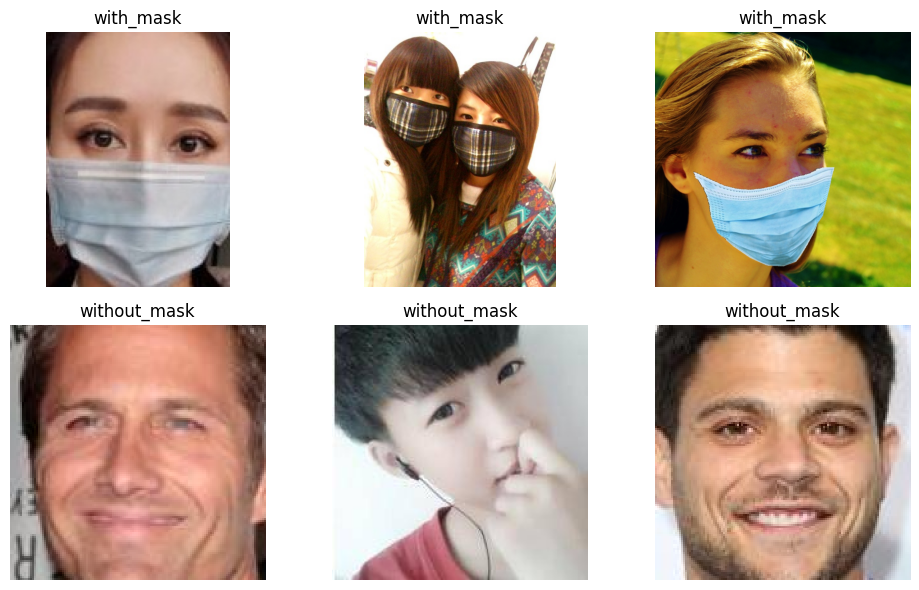

In [6]:
"""
תא 5 — הצגת תמונות לדוגמה.
הצגת שלוש תמונות מכל מחלקה לבדיקת התמונות והתוויות.
"""

plt.figure(figsize=(10, 6))
for class_index, class_name in enumerate(class_names):
    examples = random.Random(SEED).sample(class_images[class_name], 3)
    for image_index, image_path in enumerate(examples):
        with Image.open(image_path) as image:
            plt.subplot(2, 3, class_index * 3 + image_index + 1)
            plt.imshow(image.convert('RGB'))
            plt.title(class_name)
            plt.axis('off')
plt.tight_layout()
plt.show()

In [7]:
"""
תא 6 — חלוקה לאימון, אימות ובדיקה.
חלוקת קובצי כל מחלקה ל־70% אימון, 15% אימות והשאר הערכה. התמונות מועתקות בפורמט המקורי. בהרצה חוזרת נבנית מחדש רק תיקיית החלוקה המקומית של המחברת.
"""

split_dir = Path('/content/maskvision_split')
if split_dir.is_dir():
    shutil.rmtree(split_dir)
train_dir = split_dir / 'training'
val_dir = split_dir / 'validation'
test_dir = split_dir / 'evaluation'
rng = random.Random(SEED)

for class_name in class_names:
    images = class_images[class_name].copy()
    rng.shuffle(images)
    train_end = int(len(images) * 0.70)
    val_end = train_end + int(len(images) * 0.15)
    groups = {
        'training': images[:train_end],
        'validation': images[train_end:val_end],
        'evaluation': images[val_end:]
    }
    for split_name, image_paths in groups.items():
        destination = split_dir / split_name / class_name
        destination.mkdir(parents=True, exist_ok=True)
        for index, image_path in enumerate(image_paths):
            new_name = f'{class_name}_{index:05d}{image_path.suffix.lower()}'
            shutil.copy2(image_path, destination / new_name)
        print(split_name, class_name, len(image_paths), flush=True)
print('Dataset split completed.')


training with_mask 3352
validation with_mask 718
evaluation with_mask 719
training without_mask 3322
validation without_mask 712
evaluation without_mask 713
Dataset split completed.


In [8]:
"""
תא 7 — בדיקת חלוקת הנתונים.
הצגת מספר התמונות בכל קבוצה ובדיקה שסך הקבצים תואם למאגר.
"""

summary_rows = []
for split_name in ['training', 'validation', 'evaluation']:
    for class_name in class_names:
        count = len(list((split_dir / split_name / class_name).iterdir()))
        summary_rows.append({'Dataset': split_name, 'Class': class_name, 'Images': count})
split_summary = pd.DataFrame(summary_rows)
display(split_summary)
assert int(split_summary['Images'].sum()) == sum(len(images) for images in class_images.values())
split_summary.to_csv(project_dir / 'dataset_split.csv', index=False)
print('Dataset split verified.')


,Dataset,Class,Images
0,training,with_mask,3352
1,training,without_mask,3322
2,validation,with_mask,718
3,validation,without_mask,712
4,evaluation,with_mask,719
5,evaluation,without_mask,713


Dataset split verified.


In [9]:
"""
תא 8 — טעינת התמונות ונרמול.
טעינת תמונות RGB בגודל 128×128 וחלוקת הפיקסלים ב־255. רק קבוצת האימון מעורבבת.
"""

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, class_names=class_names, label_mode='int',
    image_size=IMG_SIZE, interpolation='bilinear',
    batch_size=BATCH_SIZE, shuffle=True, seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, class_names=class_names, label_mode='int',
    image_size=IMG_SIZE, interpolation='bilinear',
    batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, class_names=class_names, label_mode='int',
    image_size=IMG_SIZE, interpolation='bilinear',
    batch_size=BATCH_SIZE, shuffle=False
)

def normalize_image(images, labels):
    """מנרמל את ערכי הפיקסלים לטווח שבין אפס לאחת ומחזיר גם את התוויות."""
    return tf.cast(images, tf.float32) / 255.0, labels

train_ds = train_ds.map(normalize_image).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.map(normalize_image).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.map(normalize_image).prefetch(tf.data.AUTOTUNE)
for images, labels in train_ds.take(1):
    print('Image batch:', images.shape)
    print('Pixel range:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))


Found 6674 files belonging to 2 classes.
Found 1430 files belonging to 2 classes.
Found 1432 files belonging to 2 classes.
Image batch: (32, 128, 128, 3)
Pixel range: 0.0 1.0


In [12]:
"""
תא 9 — בניית מודל CNN.
בניית שלוש שכבות קונבולוציה ושכבת Softmax עם שני פלטים. זהו מודל חדש המאומן מאפס.
"""

model = Sequential([
    Input(shape=(*IMG_SIZE, 3)),
    Conv2D(32, 3, padding='same', activation='relu'),
    MaxPooling2D(2),
    Conv2D(64, 3, padding='same', activation='relu'),
    MaxPooling2D(2),
    Conv2D(128, 3, padding='same', activation='relu'),
    MaxPooling2D(2),
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(2, activation='softmax')
], name='MaskVision_CNN')
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy', metrics=['accuracy']
)
model.summary()


Model: "MaskVision_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,018 (429.76 KB)

 Trainable params: 110,018 (429.76 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
"""
תא 10 — אימון המודל.
אימון עד 25 מחזורים, עצירה מוקדמת ושמירת המודל בעל הפסד האימות הנמוך ביותר. קבוצת ההערכה אינה משתתפת באימון או בבחירת המודל.
"""

model_path = project_dir / 'maskvision_baseline.keras'
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True),
    CSVLogger(project_dir / 'maskvision_baseline_history.csv')
]
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=callbacks, verbose=1
)


Epoch 1/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step - accuracy: 0.8045 - loss: 0.4296 - val_accuracy: 0.8224 - val_loss: 0.4110
Epoch 2/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.8388 - loss: 0.3468 - val_accuracy: 0.8503 - val_loss: 0.3499
Epoch 3/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 20s 72ms/step - accuracy: 0.8469 - loss: 0.3225 - val_accuracy: 0.8748 - val_loss: 0.2748
Epoch 4/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.8761 - loss: 0.2712 - val_accuracy: 0.9042 - val_loss: 0.2320
Epoch 5/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.8858 - loss: 0.2584 - val_accuracy: 0.8958 - val_loss: 0.2260
Epoch 6/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 20s 73ms/step - accuracy: 0.9058 - loss: 0.2268 - val_accuracy: 0.9042 - val_loss: 0.2424
Epoch 7/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 18s 86ms/step - accuracy: 0.9137 - loss: 0.2081 - val_accuracy: 0.9147 - val_loss: 0.1877
Epoch 8/25
209/209 ━━━━━━━━━━━━━━━━━━━━ 18s 84ms/step - accuracy: 0.9183 - loss: 0.2009 - 

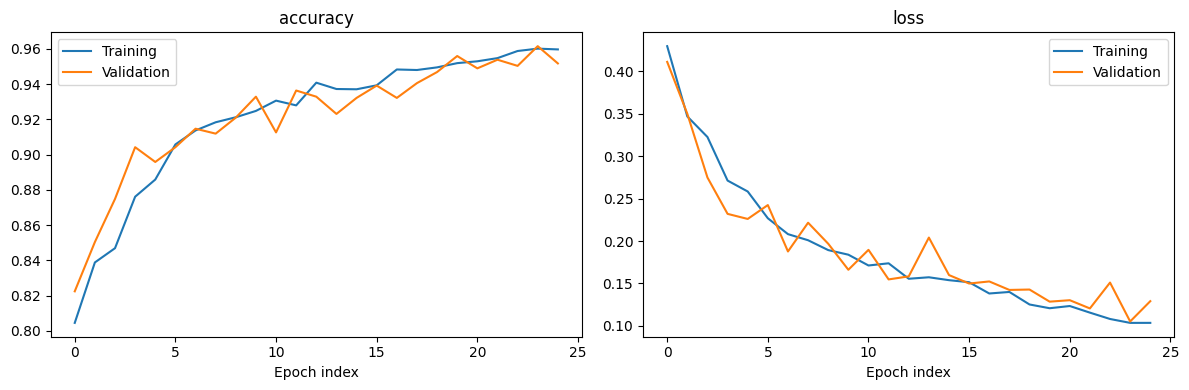

45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.9546 - loss: 0.1239
Test Accuracy: 95.46%
Test Loss: 0.1239


In [14]:
"""
תא 11 — גרפי האימון והערכת המודל.
הצגת דיוק והפסד לאורך האימון והערכת המודל השמור על קבוצת ההערכה.
"""

plt.figure(figsize=(12, 4))
for index, metric in enumerate(['accuracy', 'loss']):
    plt.subplot(1, 2, index + 1)
    plt.plot(history.history[metric], label='Training')
    plt.plot(history.history['val_' + metric], label='Validation')
    plt.title(metric)
    plt.xlabel('Epoch index')
    plt.legend()
plt.tight_layout()
plt.savefig(project_dir / 'training_curves.png', dpi=160)
plt.show()

best_model = tf.keras.models.load_model(model_path)
test_loss, test_accuracy = best_model.evaluate(test_ds)
print(f'Test Accuracy: {test_accuracy:.2%}')
print(f'Test Loss: {test_loss:.4f}')

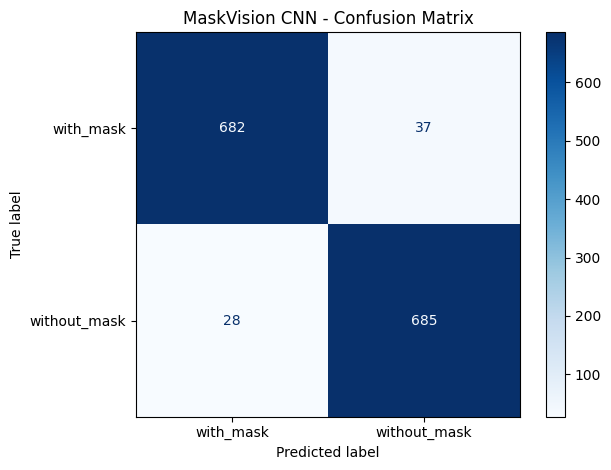

In [15]:
"""
תא 12 — מטריצת בלבול.
איסוף התוויות והתחזיות והצגת מטריצה של הסיווגים הנכונים והשגויים.
"""

y_true = []
y_pred = []
for images, labels in test_ds:
    predictions = best_model(images, training=False).numpy()
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
display_matrix = ConfusionMatrixDisplay(cm, display_labels=class_names)
display_matrix.plot(cmap='Blues', values_format='d')
plt.title('MaskVision CNN - Confusion Matrix')
plt.tight_layout()
plt.savefig(project_dir / 'confusion_matrix.png', dpi=160)
plt.show()


In [16]:
"""
תא 13 — דוח סיווג ותוצאות.
חישוב Precision, Recall ו־F1 לכל מחלקה ושמירת הדוחות והמדדים. התוצאות מתייחסות למסווג בלבד, ללא גלאי הפנים וסף Unknown.
"""

report_text = classification_report(y_true, y_pred, labels=[0, 1], target_names=class_names, digits=4, zero_division=0)
print(report_text)
report = classification_report(y_true, y_pred, labels=[0, 1], target_names=class_names, output_dict=True, zero_division=0)
report_table = pd.DataFrame(report).transpose()
report_table.index.name = ''
report_table.to_csv(project_dir / 'classification_report.csv')
(project_dir / 'classification_report.txt').write_text(report_text, encoding='utf-8')

metrics = {
    'selected_model': 'Baseline CNN', 'images': len(y_true),
    'accuracy': float(test_accuracy), 'loss': float(test_loss),
    'macro_f1': float(report['macro avg']['f1-score']), 'rounded': False,
    'source': 'MaskVision_AI_2_Classes.ipynb: held-out Evaluation split',
    'label_policy': {'incorrect_mask': 'excluded', 'with_mask': 'with_mask', 'without_mask': 'without_mask'},
    'limitations': 'Random file split; duplicate images and identities were not checked. Face detector and Unknown threshold excluded.'
}
(project_dir / 'evaluation_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
evaluation_text = f'Test Accuracy: {test_accuracy:.2%}\nTest Loss: {test_loss:.4f}\n'
(project_dir / 'evaluation_output.txt').write_text(evaluation_text, encoding='utf-8')


              precision    recall  f1-score   support

   with_mask     0.9606    0.9485    0.9545       719
without_mask     0.9488    0.9607    0.9547       713

    accuracy                         0.9546      1432
   macro avg     0.9547    0.9546    0.9546      1432
weighted avg     0.9547    0.9546    0.9546      1432



40

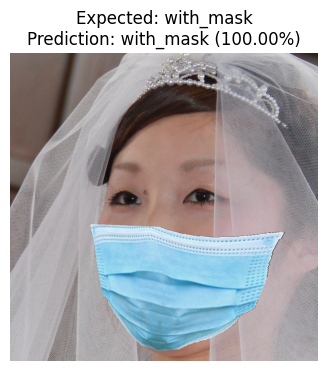

File: with_mask_00654.jpg
with_mask 100.00%
without_mask 0.00%
Correct: True



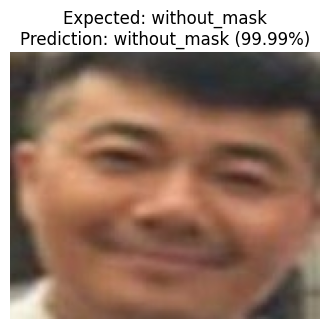

File: without_mask_00114.jpg
with_mask 0.01%
without_mask 99.99%
Correct: True



In [18]:
"""
תא 14 — חיזוי שתי תמונות מקבוצת הבדיקה.
בחירה אוטומטית של תמונה אחת עם מסכה ותמונה אחת בלי מסכה מתוך קובצי קבוצת ההערכה.
עיבוד התמונות בהתאם לאימון והצגתן לצד התווית הצפויה ותחזית המודל.
הצגת ההסתברויות לשתי המחלקות; ביטחון נמוך מ־60% מוצג כ־Unknown.
"""

rng = random.Random(SEED)

for expected_label in class_names:
    folder = test_dir / expected_label
    image_paths = []
    for image_path in sorted(folder.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            image_paths.append(image_path)

    image_path = rng.choice(image_paths)
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        pixels = tf.image.resize(
            np.asarray(image), IMG_SIZE, method='bilinear', antialias=False
        ).numpy() / 255.0

        batch = np.expand_dims(pixels, axis=0)
        scores = best_model(batch, training=False).numpy()[0]
        index = int(np.argmax(scores))
        prediction = class_names[index] if scores[index] >= 0.60 else 'Unknown'

        plt.figure(figsize=(4, 4))
        plt.imshow(image)
        plt.title(f'Expected: {expected_label}\nPrediction: {prediction} ({scores[index]:.2%})')
        plt.axis('off')
        plt.show()

    print('File:', image_path.name)
    for class_name, score in zip(class_names, scores):
        print(class_name, f'{score:.2%}')
    print('Correct:', prediction == expected_label)
    print()

In [19]:
"""
תא 15 — שמירה והורדת הקבצים.
שמירת שמות המחלקות והגדרות העיבוד, בדיקת טעינה חוזרת והורדת המודל והתוצאות. יש להוריד גם את המחברת עם הפלטים דרך File → Download → Download .ipynb.
"""

from google.colab import files

(project_dir / 'class_names.json').write_text(json.dumps(class_names, indent=4), encoding='utf-8')
preprocessing = {
    'verified': True, 'color_mode': 'RGB', 'image_size': list(IMG_SIZE),
    'resample': 'tensorflow_bilinear', 'scale_divisor': 255,
    'source': 'training/MaskVision_AI_2_Classes.ipynb, cell 8',
    'label_policy': metrics['label_policy']
}
(project_dir / 'preprocessing.json').write_text(json.dumps(preprocessing, indent=4), encoding='utf-8')
reloaded_model = tf.keras.models.load_model(model_path, compile=False)
check_images, check_labels = next(iter(test_ds))
np.testing.assert_allclose(
    best_model(check_images[:4], training=False).numpy(),
    reloaded_model(check_images[:4], training=False).numpy(), rtol=1e-5, atol=1e-6
)
print('Model reload verified.')

export_names = [
    'maskvision_baseline.keras', 'maskvision_baseline_history.csv',
    'class_names.json', 'preprocessing.json', 'evaluation_metrics.json',
    'evaluation_output.txt', 'classification_report.csv',
    'classification_report.txt', 'confusion_matrix.png',
    'training_curves.png', 'dataset_split.csv'
]
export_path = Path('/content/maskvision_export.zip')
with zipfile.ZipFile(export_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for filename in export_names:
        archive.write(project_dir / filename, arcname=filename)
files.download(str(export_path))

Model reload verified.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
"""הצגת מחזור האימון בעל הפסד האימות הנמוך ביותר והמדדים שלו."""

best_epoch = np.argmin(history.history['val_loss'])

print('Best epoch:', best_epoch + 1)
print('Validation loss:', history.history['val_loss'][best_epoch])
print('Validation accuracy:', history.history['val_accuracy'][best_epoch])

Best epoch: 24
Validation loss: 0.10520125925540924
Validation accuracy: 0.9615384340286255
